# 04 · Cliente OPC UA: subscription contra polling

**Objetivo:** entender o mecanismo que faz o OPC UA escalar: em vez de o cliente perguntar o tempo todo (**polling**), ele pede ao servidor para **avisar quando mudar** (**subscription**), e ainda pode filtrar ruído com **deadband**.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from common.notebook import load, run_in_background, require_broker
import asyncio
srv = load("03-opcua-server-model/server.py")
cli = load("04-opcua-client-subscriptions/client.py")
URL = "opc.tcp://localhost:4841/iiot-examples/"
run_in_background(lambda: srv.main("opc.tcp://0.0.0.0:4841/iiot-examples/"), port=4841)

servidor ativo na porta 4841


## 1. O cliente completo do exemplo

Ele faz, em ordem: navegar, ler metadados, chamar `Start()`, escrever o setpoint, tentar escrever numa medição (e ser recusado), e por fim assinar 4 variáveis por 8 segundos.

In [2]:
resultado = await cli.run(seconds=8, url=URL)
resultado

== browse ==
  Filler01  [Object]
    State  [Variable]
    Speed  [Variable]
    GoodCount  [Variable]
    RejectCount  [Variable]
    Temperature  [Variable]
    Setpoints  [Object]
      TargetSpeed  [Variable]
    Start  [Method]
    Stop  [Method]
    ResetCounters  [Method]

== metadata == Speed in bottles/min, range 0.0..600.0

== method calls ==
  Start() -> ok
  wrote TargetSpeed = 300
  write to Speed refused by server: BadUserAccessDenied

== subscription for 8 s (publishing interval 500 ms) ==
  19:17:28.0155  State        = 'RUNNING'
  19:17:27.8464  GoodCount    = 0
  19:17:27.8464  RejectCount  = 0


  19:17:27.8464  Speed        = 0.0
  19:17:28.3481  Speed        = 61.8


  19:17:28.8494  Speed        = 108.3
  19:17:28.8495  GoodCount    = 1


  19:17:29.3505  Speed        = 148.2
  19:17:29.3507  GoodCount    = 2


  19:17:29.8516  Speed        = 177.9
  19:17:29.8518  GoodCount    = 4


  19:17:30.3533  Speed        = 201.3
  19:17:30.3536  GoodCount    = 5


... (8 outputs left out)

  19:17:34.8664  GoodCount    = 24


  19:17:35.3675  GoodCount    = 26


  19:17:35.8682  GoodCount    = 29

  31 notifications received; polling the same 4 tags every 250 ms would have been 128 reads.
  Stop() -> ok


{'notifications': 31, 'polls': 128, 'state': 'IDLE'}

**Interpretação da saída**

* `write to Speed refused by server: BadUserAccessDenied`: a medição é protegida, como vimos no notebook 03.
* Cada linha `change` é uma **notificação** que o servidor empurrou: só chegam quando o valor muda.
* `State` aparece uma vez (mudou para RUNNING e ficou). `GoodCount` aparece a cada garrafa contada. `Speed` aparece só quando varia mais de **5 garrafas/min**, por causa do deadband.
* A última linha compara: polling das mesmas 4 tags a cada 250 ms seria **128 leituras**; a subscription trouxe bem menos mensagens, e só as que importam.

## 2. Medindo o efeito do deadband

Vamos assinar só `Speed` duas vezes, com e sem deadband, e contar as notificações.

In [3]:
from asyncua import Client, ua

class Contador:
    def __init__(self): self.n, self.valores = 0, []
    def datachange_notification(self, node, val, data):
        self.n += 1; self.valores.append(val)

async def comparar(segundos=8):
    async with Client(URL) as c:
        idx = await c.get_namespace_index(srv.NS_URI)
        f = await c.nodes.objects.get_child([f"{idx}:Plant", f"{idx}:Line1", f"{idx}:Filler01"])
        await f.call_method(f"{idx}:Start")
        await asyncio.sleep(10)                      # espera estabilizar no setpoint
        speed = await f.get_child(f"{idx}:Speed")
        sem, com = Contador(), Contador()
        sub_sem = await c.create_subscription(250, sem)
        sub_com = await c.create_subscription(250, com)
        await sub_sem.subscribe_data_change(speed, sampling_interval=250)
        await sub_com.deadband_monitor(speed, 5.0, deadbandtype=1)   # 1 = deadband absoluto
        await asyncio.sleep(segundos)                # as duas assinaturas medem AO MESMO TEMPO
        await sub_sem.delete(); await sub_com.delete()
        await f.call_method(f"{idx}:Stop")
        return sem, com

sem, com = await comparar()
print(f"sem deadband : {sem.n:3d} notificações em 8 s")
print(f"deadband 5.0 : {com.n:3d} notificações em 8 s")
print(f"faixa real da velocidade no período: {min(sem.valores):.1f} a {max(sem.valores):.1f} garrafas/min")

sem deadband :  17 notificações em 8 s
deadband 5.0 :   1 notificações em 8 s
faixa real da velocidade no período: 294.1 a 304.1 garrafas/min


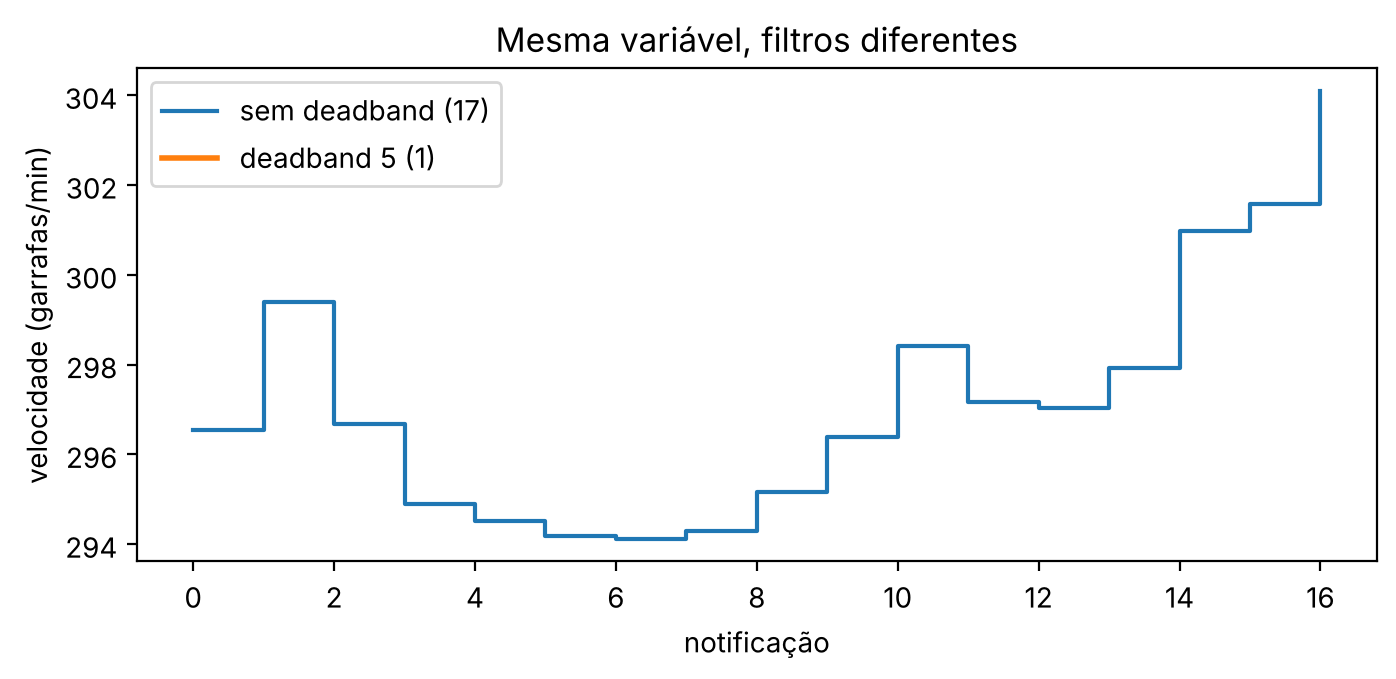

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.step(range(len(sem.valores)), sem.valores, where="post", label=f"sem deadband ({sem.n})")
ax.step(range(len(com.valores)), com.valores, where="post", label=f"deadband 5 ({com.n})", lw=2)
ax.set_xlabel("notificação"); ax.set_ylabel("velocidade (garrafas/min)"); ax.legend(); ax.set_title("Mesma variável, filtros diferentes")
plt.show()

**Interpretação:** as duas assinaturas olham a **mesma variável, no mesmo intervalo**, com a máquina já estável no setpoint. Sem deadband, cada pequena variação (o simulador adiciona ±3 garrafas/min de ruído) gera uma mensagem. Com deadband de 5, o servidor só avisa quando a velocidade se move de forma relevante. **O filtro roda no servidor**, então o ruído nem chega a ocupar a rede.

## Resumo

| | Polling | Subscription |
|---|---|---|
| Quem pergunta | o cliente, sempre | o cliente uma vez, depois o servidor avisa |
| Tráfego | constante, mesmo sem mudança | proporcional às mudanças |
| Ruído | o cliente filtra depois | **deadband** filtra na origem |
| Timestamp | hora da leitura | hora da amostra no servidor (`SourceTimestamp`) |

Em projetos reais, historiadores e SCADAs conectados a dezenas de CLPs só são viáveis com subscription.